# 04 - Study 1: gender differences in linguistic self-presentation

Women and men describe themselves differently. This notebook measures how far
the four features differ between women and men within the same occupation, and
how that difference varies with the composition of the occupation.

- **Question:** Do the biographies of women and men differ in agentic and
  communal wording, in the passive voice, in achievement verbs and in conferred
  recognition, within the same occupation?
- **Expectation:** F1 (`communal_balance`) and `communion_rate` higher for
  women, `agency_rate` lower, F2 higher, F3 lower, F4 higher; the directions
  are held as
  `expected_sign` in the result tables.
- **Status:** main analysis of Study 1, on dictionary A. The decision for A was
  taken on 2026-10-10, before any result with A was seen. The union A u B
  does not appear here; it is the robustness variant of notebook 04b.
  F1 was revised on 2026-11-13: the balance follows the
  definition of Study 2 (communal minus agentic hits per 100 words); the
  former index (A - C) / (A + C + 1) is no longer used.
- **Unit and test:** biography;
  `feature ~ female + C(occupation, Treatment("professor")) + log(word count)`
  with HC1 robust standard errors for the dense quantities, and a hurdle model
  for F3 and F4.
- **Inputs:** `outputs/df_features.parquet` from notebook 03 (dictionary A) and
  `config/occupation_metadata_27.csv` (the share of women per occupation, BLS).
- **Outputs:** the tables and figures under `outputs/study1_results/`, among
  them `study1_effect_sizes.csv`, `study1_beta_by_occupation.csv`,
  `study1_levels_by_occupation.csv`, `study1_gap_by_composition.csv`,
  `study1_gap_composition_tests.csv` and the forest plot
  `study1_forest_plot.png`.
- **Run:** from a fresh kernel, top to bottom, from the project root. Section 1
  loads the data and builds the design variables; the later sections rely on
  that.
- **Decisions:** dictionary A, the reference occupation is `professor`, the
  word count enters as a logarithm, and the directions are fixed in advance per
  quantity.


## Contents

1. **Data and sample** - loading, input checks, distributions of the dependent
   variables, design variables
2. **Main models F1-F4** - OLS with occupation fixed effects and log(word
   count), HC1; hurdle model for F3 and F4; effect-size table
3. **Forest plot** - all quantities on one common d scale
4. **Per occupation (27)** - beta_female per occupation for all six quantities
5. **Length** - interaction `female x log(word count)`
6. **Levels per occupation and composition of the occupation** - 6a
   descriptive, 6b exploratory

Numbers live in the cell outputs, not in the markdown. Each section opens with a
header cell stating the question, the expectation, the status, the unit and test,
and the output files.

## 1. Data and sample

**Question:** Are the inputs complete, and do the distributions of the dependent
variables match the model families fixed in advance?
**Expectation:** none substantive; this is the input check.
**Status:** input check, fixed on 2026-10-10.
**Unit and test:** biography (n from the file); columns complete, no missing
values, all 27 occupations present both in the data and in the occupation table.
**Output files:** `study1_results/dv_distributions.png`.

Checked here: that every column this notebook depends on is present; that no
missing values occur; that `config/occupation_metadata_27.csv` covers exactly the
occupations in the data; and how many occupations carry a BLS share of women
(the BLS publishes none for `model` and `dj`).

In [1]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

# -- Working directory to the project root -----------------------------------
if Path.cwd().name == 'notebooks':
    os.chdir('..')
print(f"CWD: {Path.cwd()}")

OUT = Path('outputs/study1_results')
OUT.mkdir(parents=True, exist_ok=True)

# -- Feature data (dictionary A, from Notebook 03) ---------------------------
df = pd.read_parquet('outputs/df_features.parquet')
print(f"Loaded: {len(df):,} biographies, {len(df.columns)} columns")

REQUIRED = ['occupation', 'gender_label', 'word_count',
            'agency_count', 'communion_count',
            'passive_ratio', 'achievement_verb_rate', 'attribution_passive_rate']
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"missing columns: {missing}"
print(f"All {len(REQUIRED)} required columns present.")

n_null = df[REQUIRED].isnull().sum()
assert n_null.sum() == 0, f"missing values:\n{n_null[n_null > 0]}"
print("No missing values in the required columns.")

# F1, the communal balance: communal minus agentic hits per 100 words, the
# scale Study 2 measures a biography and an advertisement on. Positive where a
# biography is more communal than agentic. Section 1b builds the two rates and
# controls that their difference is this column.
df['communal_balance'] = ((df['communion_count'] - df['agency_count'])
                          / df['word_count'] * 100)
print(f"communal_balance: mean={df['communal_balance'].mean():+.4f}, "
      f"sd={df['communal_balance'].std():.4f}")

# -- Release the text columns -------------------------------------------------
# No model in this notebook reads `hard_text` or `text_clean`, yet they account
# for most of the memory. This is not cosmetic: the standard error of the
# marginal effect in section 2 needs a Jacobian of shape
# (parameters x biographies x parameters) and therefore several GB. On a machine
# with 8 GB this decides whether the cell completes.
import gc
_mem_before = df.memory_usage(deep=True).sum() / 1024**2
df = df.drop(columns=[c for c in ('hard_text', 'text_clean') if c in df.columns])
gc.collect()
_mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\nText columns released: {_mem_before:,.0f} MB -> {_mem_after:,.0f} MB "
      f"({_mem_before - _mem_after:,.0f} MB freed)")
print(f"Remaining columns: {list(df.columns)}")

print(f"\nOccupations: {df['occupation'].nunique()}")
print(f"Gender: {df['gender_label'].value_counts().to_dict()}")
print(f"Share female: {(df['gender_label'] == 'Female').mean()*100:.2f}%")

# -- Occupation table: share of women from the BLS ---------------------------
occ_meta = pd.read_csv('config/occupation_metadata_27.csv')
print(f"\nocc_meta: {len(occ_meta)} rows, {len(occ_meta.columns)} columns")

occ_data = set(df['occupation'].unique())
occ_file = set(occ_meta['occ'])
assert occ_data == occ_file, (
    f"occupations differ.\n  only in the data: {sorted(occ_data - occ_file)}"
    f"\n  only in the table: {sorted(occ_file - occ_data)}")
print(f"All {len(occ_data)} occupations agree between data and occupation table.")

has_bls = occ_meta['pct_women_bls_2025'].notna()
print(f"Occupations with a BLS share of women: {has_bls.sum()} of {len(occ_meta)}")
print(f"  without a BLS value: {sorted(occ_meta.loc[~has_bls, 'occ'])}")
print(f"Match quality: {occ_meta['match'].value_counts().to_dict()}")

CWD: c:\Users\norap\OneDrive\Dokumente\Master Nova SBE\Thesis\Thesis_Model
Loaded: 393,977 biographies, 14 columns
All 8 required columns present.
No missing values in the required columns.
communal_balance: mean=+1.7914, sd=3.7461

Text columns released: 487 MB -> 75 MB (412 MB freed)
Remaining columns: ['profession', 'occupation', 'gender', 'gender_label', 'word_count', 'agentic_communal_ratio', 'agency_count', 'communion_count', 'passive_ratio', 'achievement_verb_rate', 'attribution_passive_rate_anyvoice', 'attribution_passive_rate', 'communal_balance']

Occupations: 27
Gender: {'Male': 211799, 'Female': 182178}
Share female: 46.24%

occ_meta: 27 rows, 8 columns
All 27 occupations agree between data and occupation table.
Occupations with a BLS share of women: 25 of 27
  without a BLS value: ['dj', 'model']
Match quality: {'direct': 17, 'broad': 6, 'none': 2, 'combined': 1, 'weak': 1}


**Checked here:** completeness of the required columns, absence of missing
values, the number of occupations and the gender split; further, that
`config/occupation_metadata_27.csv` covers exactly the occupations in the data
and for how many of them a BLS share of women is available. The values are in
the cell output.

### 1a. Distributions of the dependent variables

For each of the six dependent variables the cell reports the mean, the spread,
the minimum and maximum, the share of zeros and the distribution across the
range. These values decide the model family in the next section: densely
populated quantities by OLS, quantities concentrated at zero by a hurdle
model.

=== DV distribution summary ===
                            mean     std   min      max  pct_zero    skew
communal_balance          1.7914  3.7461 -25.0  38.8889   25.1966  0.6151
agency_count              0.9268  1.1686   0.0  19.0000   44.9039  1.9581
communion_count           2.0914  2.1826   0.0  28.0000   25.0969  1.7652
passive_ratio             0.0981  0.1845   0.0   3.0000   65.7711  2.8098
achievement_verb_rate     0.1930  0.6464   0.0  12.5000   89.3720  4.2601
attribution_passive_rate  0.0684  0.3727   0.0  11.1111   95.8145  7.0017


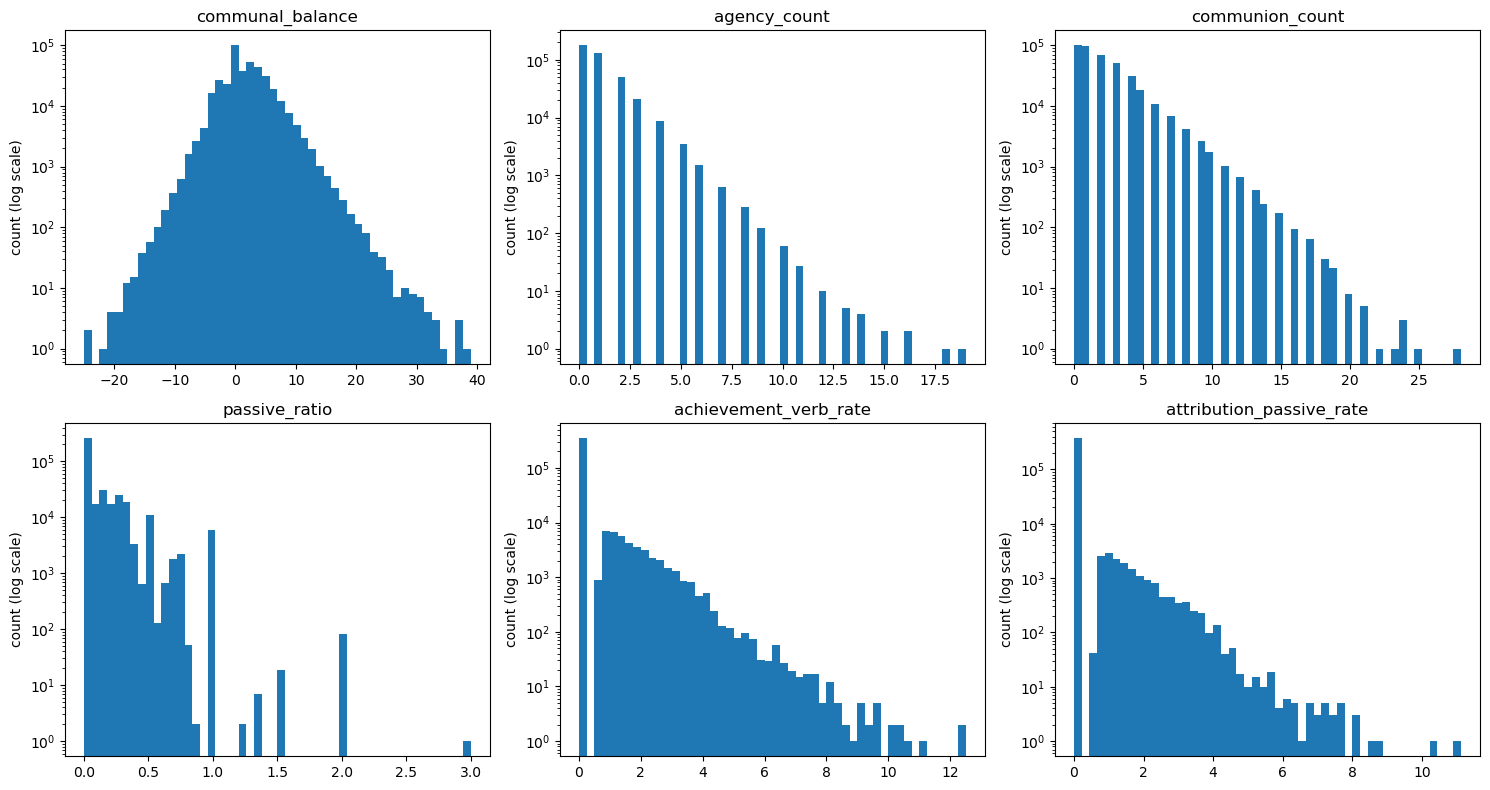

In [2]:
import matplotlib.pyplot as plt

# OUT is defined in section 1

dv_cols = ['communal_balance', 'agency_count', 'communion_count',
           'passive_ratio', 'achievement_verb_rate', 'attribution_passive_rate']

summary = df[dv_cols].agg(['mean', 'std', 'min', 'max']).T
summary['pct_zero'] = [(df[c] == 0).mean() * 100 for c in dv_cols]
summary['skew']     = [df[c].skew() for c in dv_cols]
print("=== DV distribution summary ===")
print(summary.round(4))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, dv_cols):
    ax.hist(df[col], bins=50)
    ax.set_title(col)
    ax.set_yscale('log')
    ax.set_ylabel('count (log scale)')
plt.tight_layout()
plt.savefig(OUT / 'dv_distributions.png', dpi=150)
plt.show()

**Why the model families are chosen this way.** The distributions decide that,
not the result:

- `communal_balance`, `agency_rate`, `communion_rate` and `passive_ratio`
  are densely populated and spread across their range. They are estimated by
  OLS with HC1 robust standard errors against heteroskedasticity.
- `achievement_verb_rate` (F3) and `attribution_passive_rate` (F4) are strongly
  concentrated at zero. A single linear model would conflate two different
  questions - whether such language occurs at all, and how much of it there is
  when it does. Hence a hurdle model with two stages: a logit for occurrence, a
  count model for intensity on the positive subset.

The zero shares and distribution statistics this assignment rests on are printed
by the cell above. The assignment is fixed in advance and is not revised after
the run.

### 1b. Design variables

The variables every model needs are built here:

- **`female`** - indicator, 1 for `gender_label == 'Female'`
- **`log_wc`** - log(word count) as the length control; `word_count` is at least
  7 everywhere, so the logarithm is defined
- **`f3_presence`, `f4_presence`** - occurrence (0/1) for the first hurdle stage
- **`f3_count`, `f4_count`** - counts for the second hurdle stage, recovered
  from the rate and the word count
- **`agency_rate`, `communion_rate`** - hits per 100 words; they are the two
  components of F1, and their difference is `communal_balance`

The reference category of the occupation fixed effects is `professor`, the
largest group.

In [3]:
# -- Gender indicator ----------------------------------------------
df['female'] = (df['gender_label'] == 'Female').astype(int)

# -- Length control ------------------------------------------------
# word_count min=7, so log is always finite.
df['log_wc'] = np.log(df['word_count'])

# -- Occupation reference category ---------------------------------
OCC_REF = 'professor'
occ_counts = df['occupation'].value_counts()
print(f"Occupation reference: '{OCC_REF}'  "
      f"n={occ_counts[OCC_REF]:,}  ({occ_counts[OCC_REF]/len(df)*100:.1f}% of sample)")

# -- F3/F4 presence flags (Hurdle stage 1 DV) ----------------------
df['f3_presence'] = (df['achievement_verb_rate'] > 0).astype(int)
df['f4_presence'] = (df['attribution_passive_rate'] > 0).astype(int)

# -- F3/F4 raw counts (Hurdle stage 2 DV) -------------------------
# Invert: count = round(rate x word_count / 100)
df['f3_count'] = (df['achievement_verb_rate'] * df['word_count'] / 100).round().astype(int)
df['f4_count'] = (df['attribution_passive_rate'] * df['word_count'] / 100).round().astype(int)

# -- Agency / communion per-100-word rates (F1 decomposition DVs) -
df['agency_rate']    = df['agency_count']    / df['word_count'] * 100
df['communion_rate'] = df['communion_count'] / df['word_count'] * 100

# Control: F1 is the difference of the two rates, as in Study 2.
_dev_balance = float((df['communal_balance']
                      - (df['communion_rate'] - df['agency_rate'])).abs().max())

# -- Summary -------------------------------------------------------
rows = [
    ('female',          f"{df['female'].mean()*100:.2f}% Female"),
    ('log_wc',          f"mean={df['log_wc'].mean():.3f}, sd={df['log_wc'].std():.3f}"),
    ('f3_presence',     f"{df['f3_presence'].mean()*100:.2f}% positive"),
    ('f4_presence',     f"{df['f4_presence'].mean()*100:.2f}% positive"),
    ('f3_count',        f"unconditional mean={df['f3_count'].mean():.4f}  "
                        f"| conditional (>0) mean={df.loc[df['f3_presence']==1,'f3_count'].mean():.3f}"),
    ('f4_count',        f"unconditional mean={df['f4_count'].mean():.4f}  "
                        f"| conditional (>0) mean={df.loc[df['f4_presence']==1,'f4_count'].mean():.3f}"),
    ('agency_rate',     f"mean={df['agency_rate'].mean():.3f}, sd={df['agency_rate'].std():.3f}"),
    ('communion_rate',  f"mean={df['communion_rate'].mean():.3f}, sd={df['communion_rate'].std():.3f}"),
    ('communal_balance', f"mean={df['communal_balance'].mean():.3f}, "
                         f"sd={df['communal_balance'].std():.3f}  "
                         f"| deviation from communion_rate - agency_rate: "
                         f"{_dev_balance:.1e}"),
]
print("\n=== Derived design variables ===")
for name, val in rows:
    print(f"  {name:<18s}  {val}")

Occupation reference: 'professor'  n=117,882  (29.9% of sample)

=== Derived design variables ===
  female              46.24% Female
  log_wc              mean=3.997, sd=0.472
  f3_presence         10.63% positive
  f4_presence         4.19% positive
  f3_count            unconditional mean=0.1224  | conditional (>0) mean=1.152
  f4_count            unconditional mean=0.0471  | conditional (>0) mean=1.125
  agency_rate         mean=1.595, sd=1.954
  communion_rate      mean=3.386, sd=3.201
  communal_balance    mean=1.791, sd=3.746  | deviation from communion_rate - agency_rate: 7.1e-15


**Checked here:** that the design variables are built - the indicator, the
length control, the occurrence indicators and counts for the two hurdle stages,
and the agency and communion rates per 100 words. The cell output reports the
statistics of each variable.

On the reference category: `professor` is set as the reference of the occupation
fixed effects because it is the largest group. This changes no estimate for
`female`; it only fixes what the occupation coefficients refer to.

## 2. Main models F1-F4

**Question:** Do women and men in the same occupation differ in the language of
their biographies - in the communal balance of their language (F1), in the
two components separately, in the share of passives (F2), in achievement
language (F3) and in externally attributed recognition (F4)?
**Expectation:** F1 positive (women more communal than agentic), agency
negative, communion positive, F2 positive, F3 negative, F4 positive - fixed
before the run.
**Status:** main analysis; model families fixed in advance, dictionary A fixed
on 2026-10-10.
**Unit and test:** biography; `feature ~ female + C(occupation) + log(word
count)` with HC1 for F1, `agency_rate`, `communion_rate` and F2; hurdle model
with both stages for F3 and F4.
**Output files:** `study1_results/study1_effect_sizes.csv`.

Reported per quantity: beta raw and standardised, the standard error of **the same**
coefficient that the interval and p come from, the 95 % interval, p (shown as
`< 1e-300` below the display limit), and d. For the OLS quantities d is the
standardised beta; for the logit stage it is converted from the logit coefficient
after Chinn (2000), not from the marginal effect - the marginal effect and the
logit coefficient have different standard errors, and every figure appears next
to the error that belongs to it.

The column `expected_sign` carries the direction fixed in advance. The output
does not mark whether an estimate meets it; that comparison belongs in the
interpretation, not in the table.

In [4]:
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

BASE = 'female + C(occupation, Treatment("professor")) + log_wc'
CHINN = np.sqrt(3) / np.pi          # Chinn (2000): d = beta_logit * sqrt(3)/pi
P_FLOOR = 1e-300                    # display limit for p


def fmt_p(p):
    """p as text; below the display limit shown as '< 1e-300'."""
    return "< 1e-300" if (p == 0.0 or p < P_FLOOR) else f"{p:.3e}"


ols_specs = [
    ('communal_balance',       'F1  communal_balance',       '>0'),
    ('agency_rate',            'F1a agency_rate',            '<0'),
    ('communion_rate',         'F1b communion_rate',         '>0'),
    ('passive_ratio',          'F2  passive_ratio',          '>0'),
]

results_ols = {}
print("=== 2a. OLS with HC1 robust standard errors ===")
print(f"Design: feature ~ female + C(occupation, ref='professor') + log_wc\n")

for dv, label, pred in ols_specs:
    res = smf.ols(f'{dv} ~ {BASE}', data=df).fit(cov_type='HC1')
    sd = df[dv].std()
    coef, se = res.params['female'], res.bse['female']
    ci = res.conf_int().loc['female']
    p = res.pvalues['female']
    results_ols[dv] = dict(
        label=label, pred=pred, sd=sd, n=int(res.nobs), r2=res.rsquared,
        coef=coef, se=se, ci_lo=ci.iloc[0], ci_hi=ci.iloc[1], p=p,
        # standardised: the same coefficient divided by SD(DV) -- estimate,
        # error and interval are scaled together
        std_beta=coef / sd, std_se=se / sd,
        std_ci_lo=ci.iloc[0] / sd, std_ci_hi=ci.iloc[1] / sd,
    )
    r = results_ols[dv]
    print(f"{label}   (SD of the DV = {sd:.4f})")
    print(f"  raw           beta = {coef:+.6f}   SE = {se:.6f}   "
          f"95% CI [{ci.iloc[0]:+.6f}, {ci.iloc[1]:+.6f}]")
    print(f"  standardised  beta = {r['std_beta']:+.6f}   SE = {r['std_se']:.6f}   "
          f"95% CI [{r['std_ci_lo']:+.6f}, {r['std_ci_hi']:+.6f}]")
    print(f"  p = {fmt_p(p)}   d = {r['std_beta']:+.4f}   "
          f"expected_sign = {pred}")
    print(f"  R2 = {res.rsquared:.4f}   n = {int(res.nobs):,}\n")

=== 2a. OLS with HC1 robust standard errors ===
Design: feature ~ female + C(occupation, ref='professor') + log_wc

F1  communal_balance   (SD of the DV = 3.7461)
  raw           beta = +0.529642   SE = 0.012428   95% CI [+0.505284, +0.554001]
  standardised  beta = +0.141383   SE = 0.003318   95% CI [+0.134881, +0.147885]
  p = < 1e-300   d = +0.1414   expected_sign = >0
  R2 = 0.0790   n = 393,977

F1a agency_rate   (SD of the DV = 1.9544)
  raw           beta = +0.103180   SE = 0.006470   95% CI [+0.090498, +0.115861]
  standardised  beta = +0.052793   SE = 0.003311   95% CI [+0.046304, +0.059281]
  p = 3.021e-57   d = +0.0528   expected_sign = <0
  R2 = 0.0493   n = 393,977

F1b communion_rate   (SD of the DV = 3.2010)
  raw           beta = +0.632822   SE = 0.010563   95% CI [+0.612119, +0.653525]
  standardised  beta = +0.197694   SE = 0.003300   95% CI [+0.191227, +0.204162]
  p = < 1e-300   d = +0.1977   expected_sign = >0
  R2 = 0.1080   n = 393,977

F2  passive_ratio   (SD of

In [5]:
import gc
gc.collect()

print("=== 2b. Hurdle models for F3 and F4 ===")
print("Note: the standard error of the marginal effect needs a Jacobian of")
print("shape (parameters x biographies x parameters), several GB here. Run this")
print("cell from a fresh kernel and not alongside Notebook 03.\n")
results_logit, results_count = {}, {}

hurdle_specs = [
    ('f3', 'f3_presence', 'f3_count', 'F3  achievement', '<0'),
    ('f4', 'f4_presence', 'f4_count', 'F4  attribution', '>0'),
]

for key, pres_col, cnt_col, label, pred in hurdle_specs:
    print("=" * 66)
    print(f"{label} - stage 1: occurrence (logit)")

    res = smf.logit(f'{pres_col} ~ {BASE}', data=df).fit(disp=False)

    # Marginal effect: row 'female' of the summary frame, not margeff[0] --
    # that array follows the alphabetically sorted index, where the first
    # occupation dummy sits, not female.
    fr = res.get_margeff(at='overall').summary_frame().loc['female']
    ame, ame_se, ame_p = float(fr.iloc[0]), float(fr.iloc[1]), float(fr.iloc[3])
    ame_lo, ame_hi = float(fr.iloc[4]), float(fr.iloc[5])

    # d after Chinn from the logit coefficient, with its own error
    b, b_se = res.params['female'], res.bse['female']
    b_ci = res.conf_int().loc['female']

    results_logit[key] = dict(
        label=label, pred=pred, n=int(res.nobs),
        ame=ame * 100, ame_se=ame_se * 100,
        ame_lo=ame_lo * 100, ame_hi=ame_hi * 100, ame_p=ame_p,
        logit_b=b, logit_se=b_se,
        logit_lo=b_ci.iloc[0], logit_hi=b_ci.iloc[1], logit_p=res.pvalues['female'],
        d=b * CHINN, d_lo=b_ci.iloc[0] * CHINN, d_hi=b_ci.iloc[1] * CHINN,
        base_rate=df[pres_col].mean() * 100,
    )
    r = results_logit[key]
    print(f"  share with any occurrence: {r['base_rate']:.2f}%")
    print(f"  AME     = {r['ame']:+.4f} pp   SE = {r['ame_se']:.4f} pp   "
          f"95% CI [{r['ame_lo']:+.4f}, {r['ame_hi']:+.4f}] pp   p = {fmt_p(ame_p)}")
    print(f"  beta_logit = {b:+.6f}   SE = {b_se:.6f}      "
          f"95% CI [{b_ci.iloc[0]:+.6f}, {b_ci.iloc[1]:+.6f}]   "
          f"p = {fmt_p(res.pvalues['female'])}")
    print(f"  d (Chinn) = {r['d']:+.4f}   95% CI [{r['d_lo']:+.4f}, {r['d_hi']:+.4f}]")
    print(f"  expected_sign = {pred}   n = {int(res.nobs):,}\n")

    print(f"{label} - stage 2: intensity on the positive subset (NegBin)")
    df_pos = df[df[pres_col] == 1]
    occ_vc = df_pos['occupation'].value_counts()
    print(f"  n_positive = {len(df_pos):,}   smallest occupation cell: "
          f"{occ_vc.idxmin()} (n={occ_vc.min()})")
    missing_occ = set(df['occupation'].unique()) - set(occ_vc.index)
    print(f"  occupations without positive cases: "
          f"{sorted(missing_occ) if missing_occ else 'none'}")

    try:
        res_nb = smf.negativebinomial(f'{cnt_col} ~ {BASE}',
                                       data=df_pos).fit(disp=False, maxiter=200)
        cb, cse = res_nb.params['female'], res_nb.bse['female']
        cci = res_nb.conf_int().loc['female']
        results_count[key] = dict(
            model='NegBin', coef=cb, se=cse, p=res_nb.pvalues['female'],
            irr=np.exp(cb), irr_lo=np.exp(cci.iloc[0]), irr_hi=np.exp(cci.iloc[1]),
            n=int(res_nb.nobs), alpha=float(res_nb.params.get('alpha', np.nan)))
        c = results_count[key]
        print(f"  beta_female = {cb:+.6f}   SE = {cse:.6f}   p = {fmt_p(c['p'])}")
        print(f"  IRR = {c['irr']:.4f}   95% CI [{c['irr_lo']:.4f}, {c['irr_hi']:.4f}]")
        print(f"  alpha = {c['alpha']:.6f}   n = {c['n']:,}\n")
    except Exception as e:
        results_count[key] = dict(model=f'NegBin failed: {type(e).__name__}')
        print(f"  NegBin did not converge ({type(e).__name__}); "
              f"Poisson in the cell below.\n")

    del df_pos
    gc.collect()

=== 2b. Hurdle models for F3 and F4 ===
Note: the standard error of the marginal effect needs a Jacobian of
shape (parameters x biographies x parameters), several GB here. Run this
cell from a fresh kernel and not alongside Notebook 03.

F3  achievement - stage 1: occurrence (logit)
  share with any occurrence: 10.63%
  AME     = +0.5010 pp   SE = 0.1015 pp   95% CI [+0.3021, +0.6999] pp   p = 7.956e-07
  beta_logit = +0.055195   SE = 0.011181      95% CI [+0.033281, +0.077110]   p = 7.957e-07
  d (Chinn) = +0.0304   95% CI [+0.0183, +0.0425]
  expected_sign = <0   n = 393,977

F3  achievement - stage 2: intensity on the positive subset (NegBin)
  n_positive = 41,872   smallest occupation cell: yoga_teacher (n=120)
  occupations without positive cases: none
  beta_female = -0.004006   SE = 0.009657   p = 6.783e-01
  IRR = 0.9960   95% CI [0.9773, 1.0150]
  alpha = 0.000000   n = 41,872

F4  attribution - stage 1: occurrence (logit)
  share with any occurrence: 4.19%
  AME     = -0.0803

**Methodological note - stage 2 for F4.** The Hessian of the negative binomial
model is close to singular for F4, because the counts on the positive subset
show almost no overdispersion: the dispersion parameter runs towards zero, and
there the negative binomial model is not identified. The limiting case alpha -> 0
**is** the Poisson model. F4 is therefore estimated by Poisson, not as a
fallback but because it is the distributional assumption the data support. For
F3 the negative binomial model converges and stays unchanged.

The decision follows from the convergence behaviour, not from the result; the
estimated dispersion parameter is in the cell output above.

In [6]:
# -- F4, stage 2: Poisson on the positive subset -----------------------------
# See the note above: for F4 the NegBin is not identified as alpha -> 0.
df_f4pos = df[df['f4_presence'] == 1]
res_poi = smf.poisson(f'f4_count ~ {BASE}', data=df_f4pos).fit(disp=False)

cb, cse = res_poi.params['female'], res_poi.bse['female']
cci = res_poi.conf_int().loc['female']
results_count['f4'] = dict(
    model='Poisson (NegBin alpha -> 0)', coef=cb, se=cse,
    p=res_poi.pvalues['female'], irr=np.exp(cb),
    irr_lo=np.exp(cci.iloc[0]), irr_hi=np.exp(cci.iloc[1]),
    n=int(res_poi.nobs), alpha=np.nan)

print("F4 - stage 2: Poisson on the positive subset")
print(f"  beta_female = {cb:+.6f}   SE = {cse:.6f}   "
      f"p = {fmt_p(res_poi.pvalues['female'])}")
print(f"  IRR = {np.exp(cb):.4f}   "
      f"95% CI [{np.exp(cci.iloc[0]):.4f}, {np.exp(cci.iloc[1]):.4f}]")
print(f"  n_positive = {len(df_f4pos):,}")

F4 - stage 2: Poisson on the positive subset
  beta_female = -0.005356   SE = 0.015508   p = 7.298e-01
  IRR = 0.9947   95% CI [0.9649, 1.0254]
  n_positive = 16,490


In [7]:
# -- 2c. Effect-size table ----------------------------------------------------
# One row per estimate. 'estimand' states what 'estimate' is; se, ci_lo, ci_hi
# and p always belong to exactly that estimate. d appears only where it is
# defined: the standardised beta for OLS, the Chinn conversion of the logit
# coefficient for the occurrence stage. 'expected_sign' carries the direction
# fixed in advance; whether an estimate meets it is left to the interpretation.
rows = []

for dv, r in results_ols.items():
    rows.append(dict(feature=r['label'], stage='', estimand='beta (raw)',
                     estimate=r['coef'], se=r['se'],
                     ci_lo=r['ci_lo'], ci_hi=r['ci_hi'], p=r['p'],
                     d=np.nan, d_lo=np.nan, d_hi=np.nan,
                     n=r['n'], model='OLS (HC1)', expected_sign=r['pred']))
    rows.append(dict(feature=r['label'], stage='', estimand='beta (standardised)',
                     estimate=r['std_beta'], se=r['std_se'],
                     ci_lo=r['std_ci_lo'], ci_hi=r['std_ci_hi'], p=r['p'],
                     d=r['std_beta'], d_lo=r['std_ci_lo'], d_hi=r['std_ci_hi'],
                     n=r['n'], model='OLS (HC1)', expected_sign=r['pred']))

for key, r in results_logit.items():
    rows.append(dict(feature=r['label'], stage='1 occurrence',
                     estimand='AME (percentage points)',
                     estimate=r['ame'], se=r['ame_se'],
                     ci_lo=r['ame_lo'], ci_hi=r['ame_hi'], p=r['ame_p'],
                     d=np.nan, d_lo=np.nan, d_hi=np.nan,
                     n=r['n'], model='logit', expected_sign=r['pred']))
    rows.append(dict(feature=r['label'], stage='1 occurrence',
                     estimand='beta (logit)',
                     estimate=r['logit_b'], se=r['logit_se'],
                     ci_lo=r['logit_lo'], ci_hi=r['logit_hi'], p=r['logit_p'],
                     d=r['d'], d_lo=r['d_lo'], d_hi=r['d_hi'],
                     n=r['n'], model='logit', expected_sign=r['pred']))
    c = results_count.get(key, {})
    if 'irr' in c:
        rows.append(dict(feature=r['label'], stage='2 intensity',
                         estimand='IRR', estimate=c['irr'], se=np.nan,
                         ci_lo=c['irr_lo'], ci_hi=c['irr_hi'], p=c['p'],
                         d=np.nan, d_lo=np.nan, d_hi=np.nan,
                         n=c['n'], model=c['model'], expected_sign=r['pred']))
        rows.append(dict(feature=r['label'], stage='2 intensity',
                         estimand='beta (log count rate)', estimate=c['coef'],
                         se=c['se'], ci_lo=np.log(c['irr_lo']),
                         ci_hi=np.log(c['irr_hi']), p=c['p'],
                         d=np.nan, d_lo=np.nan, d_hi=np.nan,
                         n=c['n'], model=c['model'], expected_sign=r['pred']))

df_table = pd.DataFrame(rows)
df_table['p_display'] = df_table['p'].apply(fmt_p)

print("=== 2c. Effect sizes, all estimates ===")
print("se, ci_lo, ci_hi and p belong to the estimate named in 'estimand'.\n")
with pd.option_context('display.width', 200, 'display.max_columns', 20):
    print(df_table[['feature', 'stage', 'estimand', 'estimate', 'se',
                     'ci_lo', 'ci_hi', 'p_display', 'd', 'expected_sign', 'n']]
          .to_string(index=False, float_format=lambda x: f"{x:+.6f}"))

df_table.to_csv(OUT / 'study1_effect_sizes.csv', index=False)
print(f"\nSaved to {OUT / 'study1_effect_sizes.csv'}  ({len(df_table)} rows)")

=== 2c. Effect sizes, all estimates ===
se, ci_lo, ci_hi and p belong to the estimate named in 'estimand'.

             feature        stage                estimand  estimate        se     ci_lo     ci_hi p_display         d expected_sign      n
F1  communal_balance                           beta (raw) +0.529642 +0.012428 +0.505284 +0.554001  < 1e-300       NaN            >0 393977
F1  communal_balance                  beta (standardised) +0.141383 +0.003318 +0.134881 +0.147885  < 1e-300 +0.141383            >0 393977
     F1a agency_rate                           beta (raw) +0.103180 +0.006470 +0.090498 +0.115861 3.021e-57       NaN            <0 393977
     F1a agency_rate                  beta (standardised) +0.052793 +0.003311 +0.046304 +0.059281 3.021e-57 +0.052793            <0 393977
  F1b communion_rate                           beta (raw) +0.632822 +0.010563 +0.612119 +0.653525  < 1e-300       NaN            >0 393977
  F1b communion_rate                  beta (standardised) 

### Methodological decision - comparability of effect sizes across model families

**Question:** How can effects from OLS and from logit models be compared in one
display without being equated?

**Decision:** the table carries every estimate in its own unit and names it in
the column `estimand`. Standard error, interval and p always sit next to the
estimate they belong to - a standardised beta is not reported with the standard
error of the raw beta, and the marginal effect not with the standard error of the
logit coefficient.

The forest plot in section 3 nevertheless needs one common axis. Cohen's d
serves that purpose: for the OLS quantities it is the standardised beta, for the
occurrence stage of F3 and F4 the conversion of the logit coefficient after
Chinn (2000), d = beta_logit * sqrt(3) / pi. The logit coefficient is converted, not the
marginal effect, because the Chinn formula applies to the logit scale.

**What this conversion does not achieve:** it does not make the two quantities
measurements of the same kind. A d of 0.1 from a densely populated measure and a
d of 0.1 from an occurrence indicator with a high share of zeros describe
different things. The common scale permits a comparison of magnitude, not an
equation. For the intensity stage (IRR) no d is given; there is no established
conversion for it, and an invented one would be worse than none.

## 3. Forest plot

**Question:** How large are the six gender differences relative to one another?
**Expectation:** none new; the directions are fixed in section 2.
**Status:** display of the results from section 2, no estimation of its own.
**Unit and test:** biography; common d scale (OLS: standardised beta; occurrence
stage: Chinn 2000).
**Output files:** `study1_results/study1_forest_plot.png`.

The values come from the result objects of section 2 and are not hardcoded; the
cell stops if section 2 has not been run.

Chinn (2000): d = beta_logit * sqrt(3)/pi = 0.5513

  quantity                                  d                  95% CI  source
  ------------------------------------------------------------------------------------
  F1b communion_rate                  +0.1977  [  +0.1912,   +0.2042]  standardised beta
  F1  communal_balance                +0.1414  [  +0.1349,   +0.1479]  standardised beta
  F1a agency_rate                     +0.0528  [  +0.0463,   +0.0593]  standardised beta
  F2  passive_ratio                   +0.0336  [  +0.0274,   +0.0399]  standardised beta
  F3  achievement (occurrence)        +0.0304  [  +0.0183,   +0.0425]  logit to d (Chinn)
  F4  attribution (occurrence)        -0.0115  [  -0.0299,   +0.0070]  logit to d (Chinn)


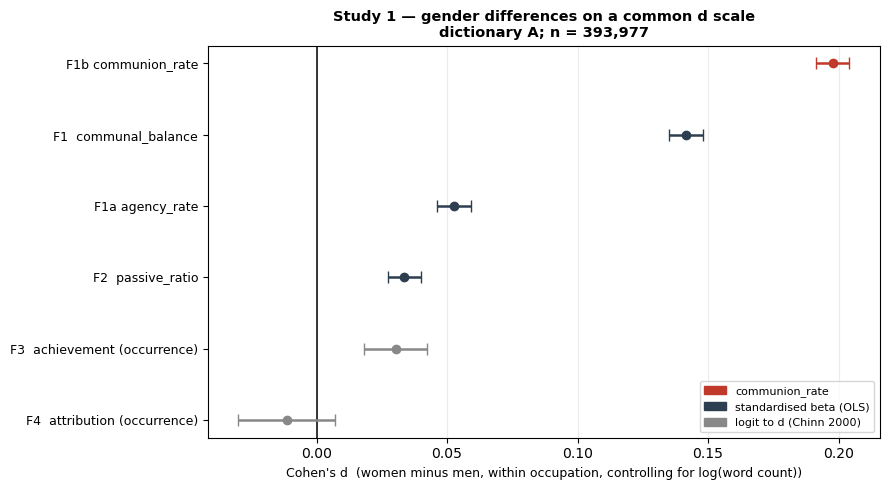


Saved to outputs\study1_results\study1_forest_plot.png


In [8]:
# -- Forest plot on a common d scale ------------------------------------------
# Values come from results_ols and results_logit (section 2), not from
# hardcoded numbers.
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

assert 'results_ols' in dir() and 'results_logit' in dir(), \
    "section 2 must have run before this cell"

print(f"Chinn (2000): d = beta_logit * sqrt(3)/pi = {CHINN:.4f}\n")

rows = []
for dv, r in results_ols.items():
    rows.append(dict(label=r['label'], d=r['std_beta'],
                     lo=r['std_ci_lo'], hi=r['std_ci_hi'],
                     source='standardised beta', communion=(dv == 'communion_rate')))
for key, r in results_logit.items():
    rows.append(dict(label=f"{r['label']} (occurrence)", d=r['d'],
                     lo=r['d_lo'], hi=r['d_hi'],
                     source='logit to d (Chinn)', communion=False))

fp = pd.DataFrame(rows)
fp['abs_d'] = fp['d'].abs()
fp = fp.sort_values('abs_d').reset_index(drop=True)   # largest effect on top

print(f"  {'quantity':<32}  {'d':>9}  {'95% CI':>22}  source")
print("  " + "-" * 84)
for _, r in fp.iloc[::-1].iterrows():
    print(f"  {r['label']:<32}  {r['d']:>+9.4f}  "
          f"[{r['lo']:>+9.4f}, {r['hi']:>+9.4f}]  {r['source']}")

COMM, GREY, DARK = '#c0392b', '#888888', '#2c3e50'
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(fp))
for i, r in fp.iterrows():
    col = COMM if r['communion'] else (DARK if r['source'].startswith('standard')
                                        else GREY)
    ax.errorbar(r['d'], i, xerr=[[r['d'] - r['lo']], [r['hi'] - r['d']]],
                fmt='o', color=col, capsize=4, linewidth=1.8, markersize=6, zorder=3)

ax.axvline(0, color='black', linewidth=1.1, zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(fp['label'], fontsize=9)
ax.set_xlabel("Cohen's d  (women minus men, within occupation, "
              "controlling for log(word count))", fontsize=9)
ax.set_title("Study 1 — gender differences on a common d scale\n"
             f"dictionary A; n = {results_ols['communion_rate']['n']:,}",
             fontsize=10.5, fontweight='bold')
ax.grid(axis='x', alpha=0.25)
ax.legend(handles=[Patch(color=COMM, label='communion_rate'),
                   Patch(color=DARK, label='standardised beta (OLS)'),
                   Patch(color=GREY, label='logit to d (Chinn 2000)')],
          fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(OUT / 'study1_forest_plot.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"\nSaved to {OUT / 'study1_forest_plot.png'}")

## 4. Per occupation (27)

**Question:** Does the difference between women and men appear in every
occupation, or do individual occupations carry it?
**Expectation:** none directional per occupation; the directions from section 2
apply to the pooled estimate, not necessarily to each occupation separately.
**Status:** breakdown of the main analysis, fixed on 2026-10-10.
**Unit and test:** biography within one occupation; per occupation
`feature ~ female + log(word count)` with HC1. For F3 and F4 the occurrence
(0/1) is estimated as a linear probability model - a simplification against the
hurdle model of the main analysis, chosen so that all six quantities are
comparable in the same unit per occupation and so that a standard error per
occupation is available for the weighted regression in 6b.
**Output files:** `study1_results/study1_beta_by_occupation.csv`,
`study1_results/study1_beta_by_occupation_counts.csv`,
`study1_results/study1_communion_by_occupation.png`,
`study1_results/study1_agency_by_occupation.png`.

All six quantities are estimated; section 6b uses these results and does not
estimate them again. Shown in full here are `communion_rate` and `agency_rate`;
for the remaining quantities the counts.

Estimated: 6 quantities x 27 occupations = 162 regressions

=== F1b communion_rate — beta_female per occupation ===
occupation                   beta        SE                 95% CI     n_F     n_M
----------------------------------------------------------------------------------
professor                 +1.0217    0.0207  [ +0.9811,  +1.0622]  53,184  64,698
teacher                   +1.0194    0.0581  [ +0.9054,  +1.1333]   9,743   6,426
dietitian                 +0.9146    0.1661  [ +0.5890,  +1.2402]   3,661     283
attorney                  +0.8227    0.0410  [ +0.7424,  +0.9030]  12,410  20,050
pastor                    +0.7005    0.1475  [ +0.4114,  +0.9897]     606   1,913
software_engineer         +0.6929    0.0936  [ +0.5094,  +0.8763]   1,089   5,797
filmmaker                 +0.6039    0.0608  [ +0.4847,  +0.7230]   2,298   4,686
yoga_teacher              +0.5062    0.1899  [ +0.1340,  +0.8783]   1,398     256
physician                 +0.4871    0.0306  [ +0.4272,  +0.54

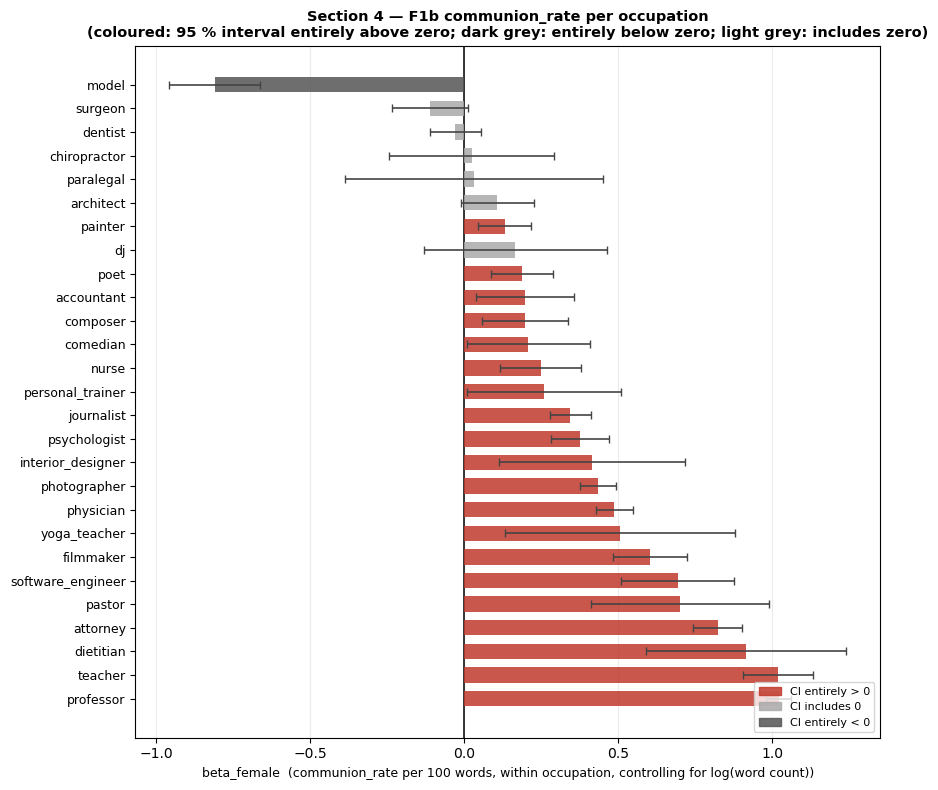

Saved to outputs\study1_results\study1_communion_by_occupation.png


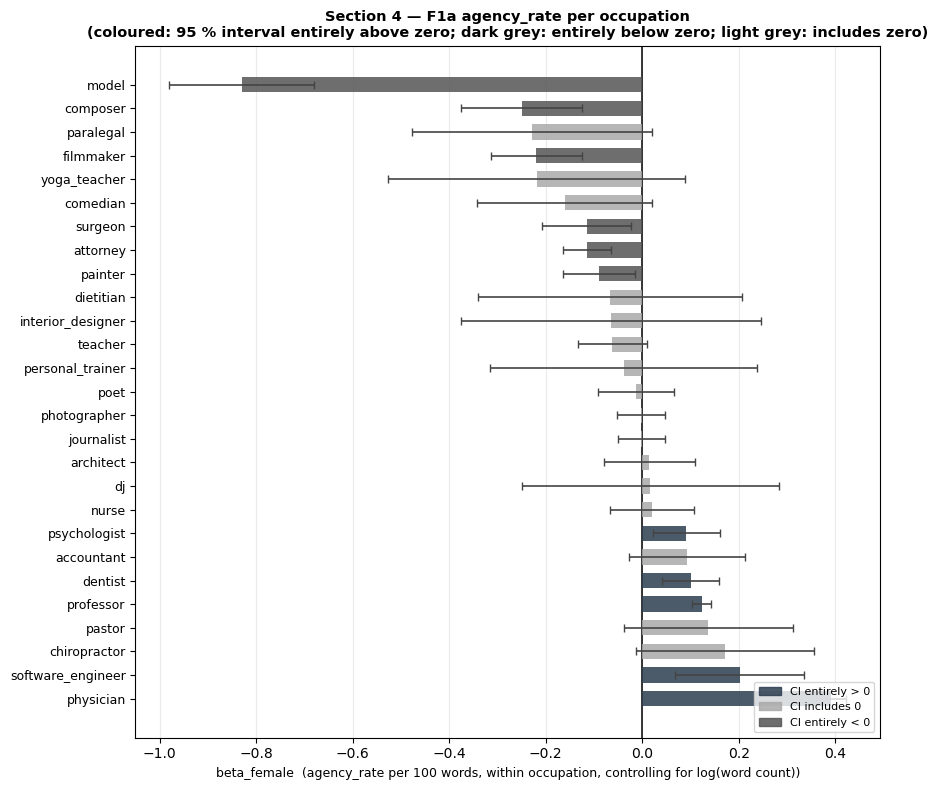

Saved to outputs\study1_results\study1_agency_by_occupation.png


In [9]:
# -- beta_female per occupation, all six quantities ---------------------------
# Specification as in 6b, step 1: OLS with HC1 for the dense quantities, a
# linear probability model for the occurrence of F3 and F4.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

QUANTITIES = [
    ('communal_balance',       'F1  communal_balance',       'OLS',  '>0'),
    ('agency_rate',            'F1a agency_rate',            'OLS',  '<0'),
    ('communion_rate',         'F1b communion_rate',         'OLS',  '>0'),
    ('passive_ratio',          'F2  passive_ratio',          'OLS',  '>0'),
    ('f3_presence',            'F3  achievement (occurrence)', 'LPM', '<0'),
    ('f4_presence',            'F4  attribution (occurrence)', 'LPM', '>0'),
]

rows = []
for dv, label, model, pred in QUANTITIES:
    for occ, sub in df.groupby('occupation'):
        res = smf.ols(f'{dv} ~ female + log_wc', data=sub).fit(cov_type='HC1')
        ci = res.conf_int().loc['female']
        rows.append(dict(
            quantity=dv, label=label, model=model, expected_sign=pred,
            occupation=occ,
            beta=res.params['female'], se=res.bse['female'],
            ci_lo=ci.iloc[0], ci_hi=ci.iloc[1], p=res.pvalues['female'],
            n=len(sub), n_female=int(sub['female'].sum()),
            n_male=int((sub['female'] == 0).sum())))

df_occ_beta = pd.DataFrame(rows)
print(f"Estimated: {len(QUANTITIES)} quantities x "
      f"{df['occupation'].nunique()} occupations = {len(df_occ_beta)} regressions\n")

# -- Full tables for communion_rate and agency_rate --------------------------
for dv in ('communion_rate', 'agency_rate'):
    dsub = (df_occ_beta[df_occ_beta['quantity'] == dv]
            .sort_values('beta', ascending=False))
    lab = dsub['label'].iloc[0]
    print(f"=== {lab} — beta_female per occupation ===")
    print(f"{'occupation':<22}  {'beta':>9}  {'SE':>8}  {'95% CI':>21}  "
          f"{'n_F':>6}  {'n_M':>6}")
    print("-" * 82)
    for _, r in dsub.iterrows():
        print(f"{r['occupation']:<22}  {r['beta']:>+9.4f}  {r['se']:>8.4f}  "
              f"[{r['ci_lo']:>+8.4f}, {r['ci_hi']:>+8.4f}]  "
              f"{r['n_female']:>6,}  {r['n_male']:>6,}")
    print()

# -- Counts for all six quantities -------------------------------------------
print("=== Counts across the 27 occupations ===")
print(f"{'quantity':<30}  {'exp':>4}  {'beta>0':>7}  {'CI>0':>5}  {'CI<0':>5}  "
      f"{'CI in expected dir.':>20}")
print("-" * 82)
counts = []
for dv, label, model, pred in QUANTITIES:
    dsub = df_occ_beta[df_occ_beta['quantity'] == dv]
    n_pos = int((dsub['beta'] > 0).sum())
    n_ci_pos = int((dsub['ci_lo'] > 0).sum())
    n_ci_neg = int((dsub['ci_hi'] < 0).sum())
    n_dir = n_ci_pos if pred == '>0' else n_ci_neg
    counts.append(dict(quantity=dv, label=label, expected_sign=pred,
                       n_occ=len(dsub), n_beta_pos=n_pos,
                       n_ci_above_zero=n_ci_pos, n_ci_below_zero=n_ci_neg,
                       n_ci_in_expected_dir=n_dir))
    print(f"{label:<30}  {pred:>4}  {n_pos:>7}  {n_ci_pos:>5}  {n_ci_neg:>5}  "
          f"{n_dir:>20}")
df_occ_counts = pd.DataFrame(counts)

df_occ_beta.to_csv(OUT / 'study1_beta_by_occupation.csv', index=False)
df_occ_counts.to_csv(OUT / 'study1_beta_by_occupation_counts.csv', index=False)
print(f"\nSaved to {OUT / 'study1_beta_by_occupation.csv'}  "
      f"({len(df_occ_beta)} rows)")
print(f"Saved to {OUT / 'study1_beta_by_occupation_counts.csv'}")


# -- Figures for communion_rate and agency_rate ------------------------------
def plot_by_occ(dv, fname, xlabel, pos_color='#c0392b'):
    dsub = (df_occ_beta[df_occ_beta['quantity'] == dv]
            .sort_values('beta', ascending=False).reset_index(drop=True))
    fig, ax = plt.subplots(figsize=(9, 8))
    cols = [pos_color if lo > 0 else ('#555555' if hi < 0 else '#aaaaaa')
            for lo, hi in zip(dsub['ci_lo'], dsub['ci_hi'])]
    y = range(len(dsub))
    ax.barh(y, dsub['beta'], color=cols, alpha=0.85, zorder=3, height=0.65)
    ax.errorbar(dsub['beta'], y,
                xerr=[dsub['beta'] - dsub['ci_lo'], dsub['ci_hi'] - dsub['beta']],
                fmt='none', color='#444444', linewidth=1.2, capsize=3, zorder=4)
    ax.axvline(0, color='black', linewidth=1.1, zorder=2)
    ax.set_yticks(list(y))
    ax.set_yticklabels(dsub['occupation'], fontsize=9)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_title(f"Section 4 — {dsub['label'].iloc[0]} per occupation\n"
                 "(coloured: 95 % interval entirely above zero; "
                 "dark grey: entirely below zero; light grey: includes zero)",
                 fontsize=10.5, fontweight='bold')
    ax.grid(axis='x', alpha=0.25)
    ax.legend(handles=[Patch(color=pos_color, alpha=.85, label='CI entirely > 0'),
                       Patch(color='#aaaaaa', alpha=.85, label='CI includes 0'),
                       Patch(color='#555555', alpha=.85, label='CI entirely < 0')],
              fontsize=8, loc='lower right')
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"Saved to {OUT / fname}")


plot_by_occ('communion_rate', 'study1_communion_by_occupation.png',
            "beta_female  (communion_rate per 100 words, within occupation, "
            "controlling for log(word count))")
plot_by_occ('agency_rate', 'study1_agency_by_occupation.png',
            "beta_female  (agency_rate per 100 words, within occupation, "
            "controlling for log(word count))", pos_color='#2c3e50')

## 5. Length

**Question:** Does the difference between women and men depend on the length of
the biography?
**Expectation:** none directional; length enters section 2 as a control, and
this section tests whether it additionally moderates the difference.
**Status:** additional analysis to the main analysis, fixed on 2026-10-10.
**Unit and test:** biography; `communion_rate ~ female x log(word count) +
C(occupation)` with HC1; reported are the interaction coefficient with its
interval and p, and $\Delta$R^2 against the model without the interaction.
**Output files:** `study1_results/study1_moderation_logwc.png`.

`communion_rate` is the dependent variable here because it shows the largest
difference in section 2; $\Delta$R^2 states how much the interaction explains beyond the
additive model.

=== Section 5 — interaction female x log(word count) ===

beta_female         = +0.215863   (difference at log_wc = 0, outside the data range)
beta_log_wc         = +0.111631   (slope for men)
beta_female:log_wc  = +0.104311   SE = 0.022162
  95% CI            = [+0.060874, +0.147748]
  p                 = 2.518e-06
  standardised      = +0.032587

Difference (women minus men) at word-count percentiles:
  percentile  word count   log_wc    difference
  ----------------------------------------------
         10%        29.0    3.367       +0.5671 pp
         25%        37.0    3.611       +0.5925 pp
         50%        55.0    4.007       +0.6339 pp
         75%        79.0    4.369       +0.6716 pp
         90%       103.0    4.635       +0.6993 pp

R2 with interaction : 0.108057
R2 additive         : 0.107999
delta R2            : 0.000058


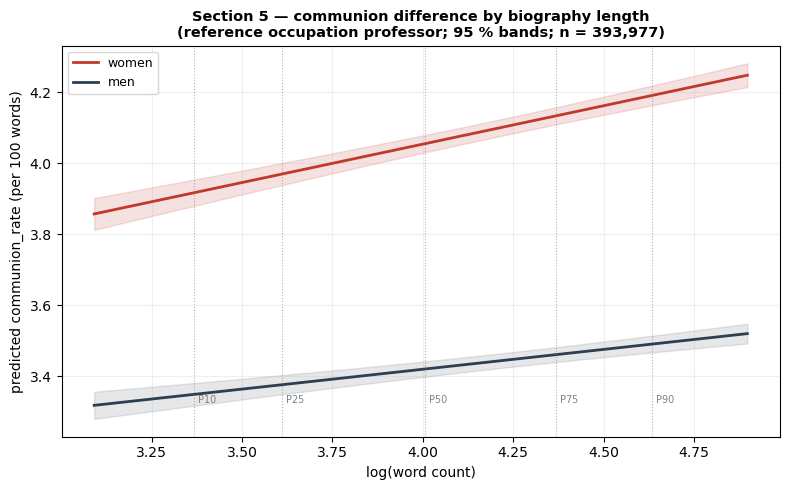


Saved to outputs\study1_results\study1_moderation_logwc.png


In [10]:
# -- Interaction female x log(word count) -------------------------------------
import matplotlib.pyplot as plt

BASE_INT = 'female * log_wc + C(occupation, Treatment("professor"))'
res_int = smf.ols(f'communion_rate ~ {BASE_INT}', data=df).fit(cov_type='HC1')

b_fem, b_logwc = res_int.params['female'], res_int.params['log_wc']
b_int = res_int.params['female:log_wc']
se_int = res_int.bse['female:log_wc']
ci_int = res_int.conf_int().loc['female:log_wc']
p_int = res_int.pvalues['female:log_wc']

print("=== Section 5 — interaction female x log(word count) ===\n")
print(f"beta_female         = {b_fem:+.6f}   (difference at log_wc = 0, "
      f"outside the data range)")
print(f"beta_log_wc         = {b_logwc:+.6f}   (slope for men)")
print(f"beta_female:log_wc  = {b_int:+.6f}   SE = {se_int:.6f}")
print(f"  95% CI            = [{ci_int.iloc[0]:+.6f}, {ci_int.iloc[1]:+.6f}]")
print(f"  p                 = {fmt_p(p_int)}")
print(f"  standardised      = {b_int / df['communion_rate'].std():+.6f}")

print(f"\nDifference (women minus men) at word-count percentiles:")
print(f"  {'percentile':>10}  {'word count':>10}  {'log_wc':>7}  {'difference':>12}")
print("  " + "-" * 46)
for pct in (10, 25, 50, 75, 90):
    wc = np.percentile(df['word_count'], pct)
    print(f"  {pct:>9}%  {wc:>10.1f}  {np.log(wc):>7.3f}  "
          f"{b_fem + b_int * np.log(wc):>+12.4f} pp")

res_add = smf.ols(
    'communion_rate ~ female + log_wc + C(occupation, Treatment("professor"))',
    data=df).fit(cov_type='HC1')
print(f"\nR2 with interaction : {res_int.rsquared:.6f}")
print(f"R2 additive         : {res_add.rsquared:.6f}")
print(f"delta R2            : {res_int.rsquared - res_add.rsquared:.6f}")

# -- Figure: predicted communion_rate over log(word count) -------------------
lwc = np.linspace(df['log_wc'].quantile(0.01), df['log_wc'].quantile(0.99), 300)


def pred_ci(female_val):
    pf = pd.DataFrame({'female': female_val, 'log_wc': lwc,
                        'occupation': 'professor'})
    fr = res_int.get_prediction(pf).summary_frame(alpha=0.05)
    return fr['mean'].values, fr['mean_ci_lower'].values, fr['mean_ci_upper'].values


y_m, lo_m, hi_m = pred_ci(0)
y_f, lo_f, hi_f = pred_ci(1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lwc, y_f, color='#c0392b', linewidth=2, label='women')
ax.fill_between(lwc, lo_f, hi_f, color='#c0392b', alpha=0.15)
ax.plot(lwc, y_m, color='#2c3e50', linewidth=2, label='men')
ax.fill_between(lwc, lo_m, hi_m, color='#2c3e50', alpha=0.12)
for pct in (10, 25, 50, 75, 90):
    xp = np.log(np.percentile(df['word_count'], pct))
    ax.axvline(xp, color='grey', linestyle=':', linewidth=0.8, alpha=0.6)
    ax.text(xp + 0.01, min(y_m[0], y_f[0]), f'P{pct}', fontsize=7,
            color='grey', va='bottom')
ax.set_xlabel('log(word count)', fontsize=10)
ax.set_ylabel('predicted communion_rate (per 100 words)', fontsize=10)
ax.set_title("Section 5 — communion difference by biography length\n"
             f"(reference occupation professor; 95 % bands; n = {int(res_int.nobs):,})",
             fontsize=10.5, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / 'study1_moderation_logwc.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"\nSaved to {OUT / 'study1_moderation_logwc.png'}")

## 6. Levels per occupation and composition of the occupation

Two parts. **6a** describes how high the quantities sit in the individual
occupations - for all biographies and separately for women and men. **6b** takes
the difference *within* each occupation from section 4 and asks whether it is
related to the share of women in that occupation.

The separation matters, because the two parts measure different things. The
level of an occupation contains the content of the occupation: nursing
biographies say "care" because the work is care, not because the writer adapts.
The difference within an occupation compares women with men of the same
occupation and therefore holds the content constant. Only 6b can say anything
about differing presentation at all; 6a stays descriptive.

The share of women comes in two variants: from the BLS via
`config/occupation_metadata_27.csv` (the BLS publishes no value for `model` and
`dj`, leaving 25 occupations there) and from the biographies themselves. Both are
reported throughout.

### 6a. Levels per occupation (descriptive)

**Question:** Do occupations with a high share of women write more communally
overall, and does that also hold for the men in those occupations?
**Expectation:** none directional; the counterpart to the exploratory analysis
of the job advertisements in Study 2.
**Status:** descriptive, fixed on 2026-10-10.
**Unit and test:** occupation (n = 27); Spearman rho between the level and the
share of women, separately for all biographies, for women and for men; p from
10,000 permutations (`seed=42`). No conclusion about presentation, because the
levels contain the content of the occupation.
**Output files:** `study1_results/study1_levels_by_occupation.csv`,
`study1_results/study1_levels_by_occupation_tests.csv`,
`study1_results/study1_levels_by_composition.png`.

Share of women: 25 occupations with a BLS value, 27 with a value from the biographies
  BLS  from 20.3% to 91.7%
  bios from 14.2% to 92.8%
  Spearman BLS against bios: rho=+0.8671

=== 6a. Spearman: level against the share of women (n=27 and 25) ===
p from 10,000 permutations, seed=42

quantity                        series   share    n       rho    p_perm
----------------------------------------------------------------------------
F1  communal_balance            all      BLS     25   +0.2670    0.2010
F1  communal_balance            all      bios    27   +0.3938    0.0480
F1  communal_balance            women    BLS     25   +0.2466    0.2379
F1  communal_balance            women    bios    27   +0.3370    0.0935
F1  communal_balance            men      BLS     25   +0.1408    0.5049
F1  communal_balance            men      bios    27   +0.2802    0.1600

F1a agency_rate                 all      BLS     25   -0.0115    0.9552
F1a agency_rate                 all      bios    27   -0.0

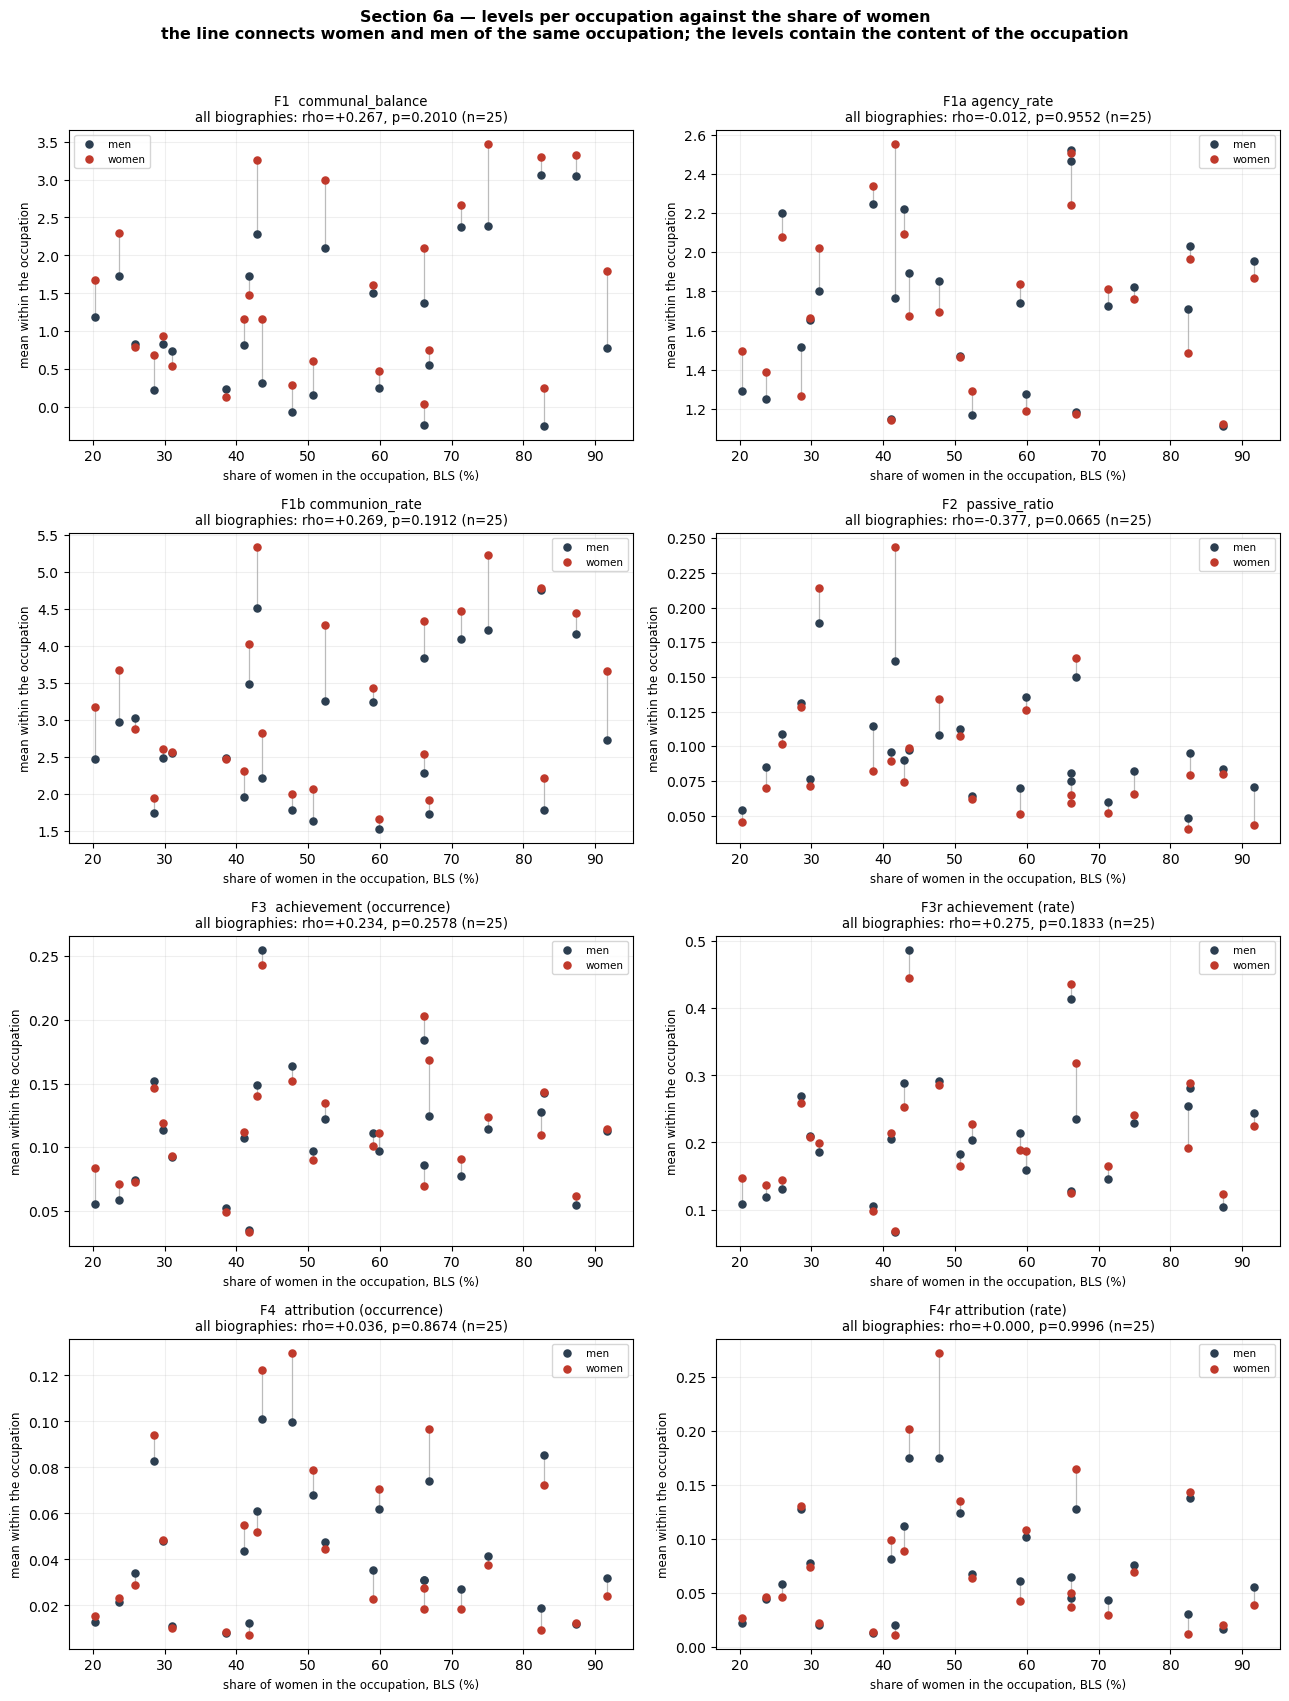

Saved to outputs\study1_results\study1_levels_by_composition.png


In [11]:
# -- 6a. Levels per occupation ------------------------------------------------
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

PERM_N, PERM_SEED = 10_000, 42

# For 6a the rates of F3 and F4 as well, not only the occurrence
MEASURES_6A = [
    ('communal_balance',         'F1  communal_balance'),
    ('agency_rate',              'F1a agency_rate'),
    ('communion_rate',           'F1b communion_rate'),
    ('passive_ratio',            'F2  passive_ratio'),
    ('f3_presence',              'F3  achievement (occurrence)'),
    ('achievement_verb_rate',    'F3r achievement (rate)'),
    ('f4_presence',              'F4  attribution (occurrence)'),
    ('attribution_passive_rate', 'F4r attribution (rate)'),
]

# -- Share of women per occupation: BLS and from the biographies -------------
share = (occ_meta[['occ', 'pct_women_bls_2025', 'match']]
         .rename(columns={'occ': 'occupation', 'pct_women_bls_2025': 'pct_bls'}))
share['pct_bios'] = (df.groupby('occupation')['female'].mean() * 100).reindex(
    share['occupation']).values
assert share['pct_bios'].notna().all(), "share of women from the biographies incomplete"
print(f"Share of women: {share['pct_bls'].notna().sum()} occupations with a BLS "
      f"value, {len(share)} with a value from the biographies")
print(f"  BLS  from {share['pct_bls'].min():.1f}% to {share['pct_bls'].max():.1f}%")
print(f"  bios from {share['pct_bios'].min():.1f}% to {share['pct_bios'].max():.1f}%")
print(f"  Spearman BLS against bios: "
      f"rho={spearmanr(share['pct_bls'], share['pct_bios'], nan_policy='omit')[0]:+.4f}\n")


def perm_spearman(x, y, n_perm=PERM_N, seed=PERM_SEED):
    """Spearman rho with a two-sided p from permutations of y."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 4:
        return np.nan, np.nan, len(x)
    rho = spearmanr(x, y)[0]
    rng = np.random.default_rng(seed)
    yp = y.copy()
    cnt = 0
    for _ in range(n_perm):
        rng.shuffle(yp)
        if abs(spearmanr(x, yp)[0]) >= abs(rho) - 1e-12:
            cnt += 1
    return rho, (1 + cnt) / (1 + n_perm), len(x)


# -- Levels per occupation and quantity --------------------------------------
lvl_rows = []
for occ, sub in df.groupby('occupation'):
    f_, m_ = sub[sub['female'] == 1], sub[sub['female'] == 0]
    for col, label in MEASURES_6A:
        lvl_rows.append(dict(
            occupation=occ, measure=col, label=label,
            mean_all=sub[col].mean(), mean_female=f_[col].mean(),
            mean_male=m_[col].mean(),
            n_all=len(sub), n_female=len(f_), n_male=len(m_)))
df_levels = pd.DataFrame(lvl_rows).merge(share, on='occupation', how='left')

# -- Spearman per quantity, per series, per measure of the share ------------
print("=== 6a. Spearman: level against the share of women (n=27 and 25) ===")
print(f"p from {PERM_N:,} permutations, seed={PERM_SEED}\n")
print(f"{'quantity':<30}  {'series':<7}  {'share':<5}  {'n':>3}  "
      f"{'rho':>8}  {'p_perm':>8}")
print("-" * 76)
sp_rows = []
for col, label in MEASURES_6A:
    dsub = df_levels[df_levels['measure'] == col]
    for series, mcol in (('all', 'mean_all'), ('women', 'mean_female'),
                         ('men', 'mean_male')):
        for xname, xcol in (('BLS', 'pct_bls'), ('bios', 'pct_bios')):
            rho, p, n = perm_spearman(dsub[xcol], dsub[mcol])
            sp_rows.append(dict(measure=col, label=label, series=series,
                                 share=xname, n=n, rho=rho, p_perm=p))
            print(f"{label:<30}  {series:<7}  {xname:<5}  {n:>3}  "
                  f"{rho:>+8.4f}  {p:>8.4f}")
    print()
df_levels_tests = pd.DataFrame(sp_rows)

df_levels.to_csv(OUT / 'study1_levels_by_occupation.csv', index=False)
df_levels_tests.to_csv(OUT / 'study1_levels_by_occupation_tests.csv', index=False)
print(f"Saved to {OUT / 'study1_levels_by_occupation.csv'}  "
      f"({len(df_levels)} rows)")
print(f"Saved to {OUT / 'study1_levels_by_occupation_tests.csv'}  "
      f"({len(df_levels_tests)} rows)")

# -- Figure: level against the BLS share, women and men connected -----------
fig, axes = plt.subplots(4, 2, figsize=(13, 17))
for ax, (col, label) in zip(axes.ravel(), MEASURES_6A):
    dsub = df_levels[df_levels['measure'] == col].dropna(subset=['pct_bls'])
    for _, r in dsub.iterrows():
        ax.plot([r['pct_bls']] * 2, [r['mean_male'], r['mean_female']],
                color='#bbbbbb', linewidth=0.9, zorder=1)
    ax.scatter(dsub['pct_bls'], dsub['mean_male'], s=26, color='#2c3e50',
               label='men', zorder=3)
    ax.scatter(dsub['pct_bls'], dsub['mean_female'], s=26, color='#c0392b',
               label='women', zorder=3)
    rho_a, p_a, n_a = perm_spearman(dsub['pct_bls'], dsub['mean_all'])
    ax.set_title(f"{label}\nall biographies: rho={rho_a:+.3f}, p={p_a:.4f} (n={n_a})",
                 fontsize=9.5)
    ax.set_xlabel('share of women in the occupation, BLS (%)', fontsize=8.5)
    ax.set_ylabel('mean within the occupation', fontsize=8.5)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7.5, loc='best')
fig.suptitle("Section 6a — levels per occupation against the share of women\n"
             "the line connects women and men of the same occupation; "
             "the levels contain the content of the occupation",
             fontsize=11.5, fontweight='bold', y=0.998)
plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.savefig(OUT / 'study1_levels_by_composition.png', dpi=180, bbox_inches='tight')
plt.show()
print(f"Saved to {OUT / 'study1_levels_by_composition.png'}")

### 6b. Differences within the occupation and composition of the occupation

**Question:** Is the difference between women and men of the same occupation
smaller in male-dominated occupations than in female-dominated ones, and not
only for communion but for the remaining quantities as well?
**Expectation (Nora, 2026-10-10):** adaptation. In male-dominated occupations
the differences in the direction of the Study 1 hypotheses are smaller. The
slope of beta_female over the share of women therefore carries the sign of the
Study 1 hypothesis for each quantity: communion +, passive (F2) +, attribution
(F4) +; F1 +; agency -, achievement (F3) -.
**Status:** exploratory, fixed on 2026-10-10. The beta per occupation for communion
and agency were known from the earlier run; their relation to the share of women
was not. Six quantities and two measures of the share of women: all results are
reported, none selected.
**Unit and test:** difference within the occupation (men of the same occupation
as the comparison, so that the content of the occupation does not appear as
adaptation); relation across occupations, n = 27, and 25 with a BLS value.
Spearman with p from 10,000 permutations (`seed=42`); weighted regression
beta_j ~ share of women with weights 1/SE_j^2 and HC1; leave-one-out; additionally
the occupations with `match == "direct"` only.
**Output files:** `study1_results/study1_gap_by_composition.csv`,
`study1_results/study1_gap_composition_tests.csv`,
`study1_results/study1_gap_by_composition.png`.

The beta per occupation come from section 4 and are not estimated again here.

**On the multiplicity correction:** Holm is applied to the p-values of the
**weighted regression** - the p of the slope, not the permutation p of the
Spearman coefficient. It runs across the six quantities within each measure of
the share of women and each subset, so each family comprises six tests. The
permutation p is reported uncorrected alongside; the two procedures answer
different questions and are not combined.

Saved to outputs\study1_results\study1_gap_by_composition.csv  (162 rows)

=== 6b. Relation across the occupations ===
Spearman p from 10,000 permutations (seed=42); slope from the weighted regression (1/SE^2, HC1).
Holm corrects the p-values of the weighted regression, across the six quantities within each group.

-- share of women: BLS   subset: all --
quantity                        exp    n      rho   p_perm       slope         SE     95% CI of the slope         p   p_holm
--------------------------------------------------------------------------------------------------------------------------------
F1  communal_balance              +   25   +0.237   0.2517    +0.00737    0.00577  [ -0.00394,  +0.01869]    0.2016   1.0000
F1a agency_rate                   -   25   -0.273   0.1860    -0.00248    0.00298  [ -0.00833,  +0.00337]    0.4062   1.0000
F1b communion_rate                +   25   +0.175   0.3985    +0.00502    0.00513  [ -0.00504,  +0.01508]    0.3279   1.0000
F2  passive_ra

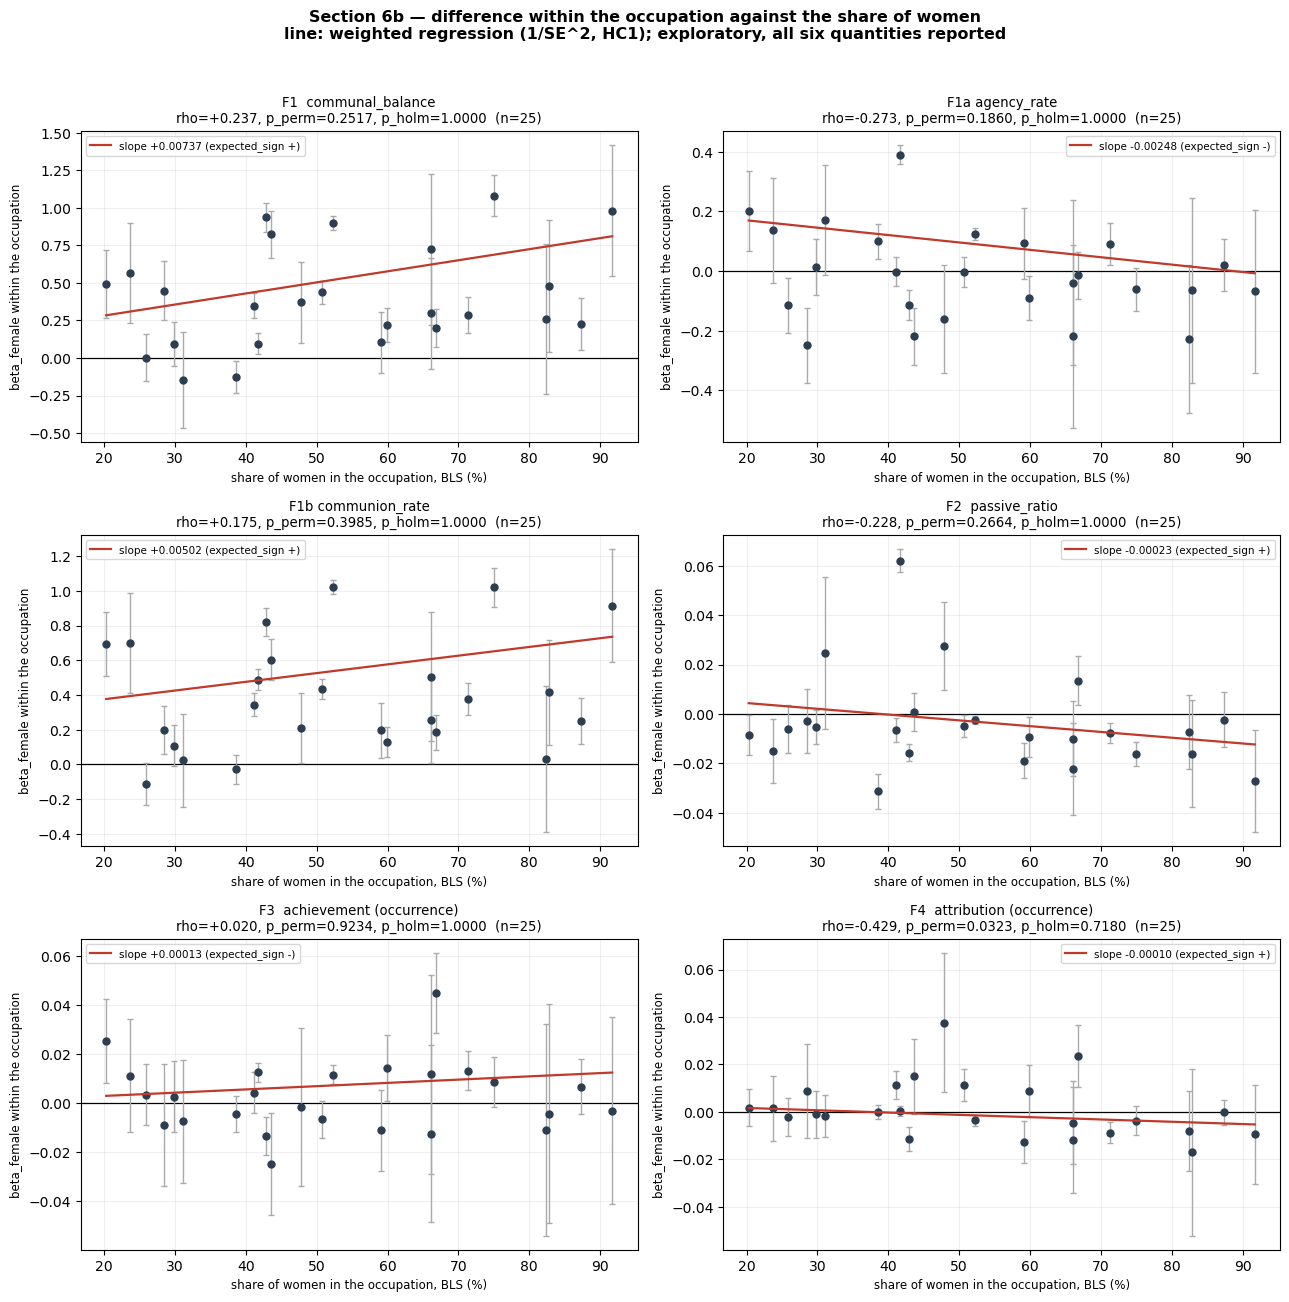


Saved to outputs\study1_results\study1_gap_by_composition.png


In [12]:
# -- 6b. Difference per occupation against the share of women -----------------
assert 'df_occ_beta' in dir(), "section 4 must have run before this cell"

gap = df_occ_beta.merge(share, on='occupation', how='left')
gap.to_csv(OUT / 'study1_gap_by_composition.csv', index=False)
print(f"Saved to {OUT / 'study1_gap_by_composition.csv'}  ({len(gap)} rows)")

EXPECTED_SIGN = {'communal_balance': '+', 'agency_rate': '-',
                 'communion_rate': '+', 'passive_ratio': '+',
                 'f3_presence': '-', 'f4_presence': '+'}


def wls_slope(d_in, xcol):
    """beta_j ~ share of women, weights 1/SE^2, HC1.

    Returns slope, SE, p, the interval bounds and n. The interval comes from the
    model rather than from slope +- 1.96*SE, so that it is consistent with the
    SE and p reported next to it.
    """
    dd = d_in.dropna(subset=[xcol, 'beta', 'se'])
    dd = dd[dd['se'] > 0]
    if len(dd) < 4:
        return (np.nan,) * 5 + (len(dd),)
    r = smf.wls('beta ~ x', data=dd.assign(x=dd[xcol]),
                weights=1.0 / dd['se'] ** 2).fit(cov_type='HC1')
    ci = r.conf_int().loc['x']
    return (float(r.params['x']), float(r.bse['x']), float(r.pvalues['x']),
            float(ci.iloc[0]), float(ci.iloc[1]), len(dd))


def holm(pvals):
    """Holm-corrected p-values, input order preserved."""
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    idx = np.where(np.isfinite(p))[0]
    order = idx[np.argsort(p[idx])]
    m, run = len(order), 0.0
    for i, j in enumerate(order):
        run = max(run, (m - i) * p[j])
        out[j] = min(run, 1.0)
    return out


rows = []
for xname, xcol in (('BLS', 'pct_bls'), ('bios', 'pct_bios')):
    for subset_name, mfilter in (('all', None), ('direct', 'direct')):
        if xname == 'bios' and mfilter is not None:
            continue                 # 'direct' concerns the BLS match only
        for dv, label, model, pred in QUANTITIES:
            dsub = gap[gap['quantity'] == dv]
            if mfilter is not None:
                dsub = dsub[dsub['match'] == mfilter]
            rho, p_perm, n_rho = perm_spearman(dsub[xcol], dsub['beta'])
            slope, slope_se, slope_p, slope_lo, slope_hi, n_w = \
                wls_slope(dsub, xcol)

            # Leave-one-out across the occupations with a valid share
            dv_ok = dsub.dropna(subset=[xcol])
            loo_rho, loo_slope = [], []
            for occ in dv_ok['occupation']:
                dd = dv_ok[dv_ok['occupation'] != occ]
                loo_rho.append(spearmanr(dd[xcol], dd['beta'])[0])
                loo_slope.append(wls_slope(dd, xcol)[0])
            rows.append(dict(
                test='rho+wls', y=dv, label=label, x=xname, subset=subset_name,
                expected_sign=EXPECTED_SIGN[dv], n=n_rho,
                rho=rho, p_perm=p_perm,
                slope=slope, se=slope_se, p=slope_p,
                slope_ci_lo=slope_lo, slope_ci_hi=slope_hi, n_wls=n_w,
                loo_rho_min=np.nanmin(loo_rho) if loo_rho else np.nan,
                loo_rho_max=np.nanmax(loo_rho) if loo_rho else np.nan,
                loo_min=np.nanmin(loo_slope) if loo_slope else np.nan,
                loo_max=np.nanmax(loo_slope) if loo_slope else np.nan))

df_gap_tests = pd.DataFrame(rows)

# Holm per measure of the share and per subset, across the six quantities.
# It corrects the p-values of the weighted regression, not the permutation p.
df_gap_tests['p_holm'] = np.nan
for (xn, sn), grp in df_gap_tests.groupby(['x', 'subset']):
    df_gap_tests.loc[grp.index, 'p_holm'] = holm(grp['p'].values)


def slope_interval_position(r):
    """Where the interval of the slope sits relative to zero."""
    if not np.isfinite(r['slope']) or not np.isfinite(r['slope_ci_lo']):
        return 'not estimable'
    if r['slope_ci_lo'] > 0:
        return 'interval entirely above zero'
    if r['slope_ci_hi'] < 0:
        return 'interval entirely below zero'
    return 'interval includes zero'


df_gap_tests['slope_interval'] = df_gap_tests.apply(slope_interval_position, axis=1)

print(f"\n=== 6b. Relation across the occupations ===")
print(f"Spearman p from {PERM_N:,} permutations (seed={PERM_SEED}); slope from "
      f"the weighted regression (1/SE^2, HC1).")
print(f"Holm corrects the p-values of the weighted regression, across the six "
      f"quantities within each group.\n")
for (xn, sn), grp in df_gap_tests.groupby(['x', 'subset']):
    print(f"-- share of women: {xn}   subset: {sn} --")
    print(f"{'quantity':<30}  {'exp':>3}  {'n':>3}  {'rho':>7}  {'p_perm':>7}  "
          f"{'slope':>10}  {'SE':>9}  {'95% CI of the slope':>22}  "
          f"{'p':>8}  {'p_holm':>7}")
    print("-" * 128)
    for _, r in grp.iterrows():
        print(f"{r['label']:<30}  {r['expected_sign']:>3}  {r['n']:>3}  "
              f"{r['rho']:>+7.3f}  {r['p_perm']:>7.4f}  "
              f"{r['slope']:>+10.5f}  {r['se']:>9.5f}  "
              f"[{r['slope_ci_lo']:>+9.5f}, {r['slope_ci_hi']:>+9.5f}]  "
              f"{r['p']:>8.4f}  {r['p_holm']:>7.4f}")
    print()
    print(f"{'quantity':<30}  leave-one-out: rho from..to / slope from..to"
          f"       interval of the slope")
    print("-" * 124)
    for _, r in grp.iterrows():
        print(f"{r['label']:<30}  rho [{r['loo_rho_min']:+.3f}, "
              f"{r['loo_rho_max']:+.3f}]  slope [{r['loo_min']:+.5f}, "
              f"{r['loo_max']:+.5f}]   {r['slope_interval']}")
    print()

df_gap_tests.to_csv(OUT / 'study1_gap_composition_tests.csv', index=False)
print(f"Saved to {OUT / 'study1_gap_composition_tests.csv'}  "
      f"({len(df_gap_tests)} rows)")

# -- Table per quantity, sorted by the BLS share (male-dominated first) -----
print(f"\n=== beta_female per occupation, sorted by the BLS share of women ===")
for dv, label, model, pred in QUANTITIES:
    dsub = (gap[gap['quantity'] == dv]
            .sort_values('pct_bls', na_position='last'))
    print(f"\n-- {label}   (expected_sign of the slope: {EXPECTED_SIGN[dv]}) --")
    print(f"{'occupation':<20}  {'BLS%':>6}  {'bios%':>6}  {'match':<9}  "
          f"{'beta':>9}  {'95% CI':>21}")
    print("-" * 82)
    for _, r in dsub.iterrows():
        bls = f"{r['pct_bls']:.1f}" if np.isfinite(r['pct_bls']) else "n/a"
        print(f"{r['occupation']:<20}  {bls:>6}  {r['pct_bios']:>6.1f}  "
              f"{str(r['match']):<9}  {r['beta']:>+9.4f}  "
              f"[{r['ci_lo']:>+8.4f}, {r['ci_hi']:>+8.4f}]")

# -- Figure: beta with interval against the BLS share, per quantity ---------
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, (dv, label, model, pred) in zip(axes.ravel(), QUANTITIES):
    dsub = gap[gap['quantity'] == dv].dropna(subset=['pct_bls'])
    ax.errorbar(dsub['pct_bls'], dsub['beta'],
                yerr=[dsub['beta'] - dsub['ci_lo'], dsub['ci_hi'] - dsub['beta']],
                fmt='o', color='#2c3e50', ecolor='#aaaaaa',
                markersize=5, capsize=2, linewidth=1, zorder=3)
    t = df_gap_tests[(df_gap_tests['y'] == dv) & (df_gap_tests['x'] == 'BLS')
                      & (df_gap_tests['subset'] == 'all')].iloc[0]
    if np.isfinite(t['slope']):
        xs = np.linspace(dsub['pct_bls'].min(), dsub['pct_bls'].max(), 50)
        dd = dsub[dsub['se'] > 0]
        r = smf.wls('beta ~ x', data=dd.assign(x=dd['pct_bls']),
                    weights=1.0 / dd['se'] ** 2).fit(cov_type='HC1')
        ax.plot(xs, r.params['Intercept'] + r.params['x'] * xs,
                color='#c0392b', linewidth=1.6, zorder=4,
                label=f"slope {t['slope']:+.5f} "
                      f"(expected_sign {t['expected_sign']})")
        ax.legend(fontsize=7.5, loc='best')
    ax.axhline(0, color='black', linewidth=0.9, zorder=2)
    ax.set_title(f"{label}\nrho={t['rho']:+.3f}, p_perm={t['p_perm']:.4f}, "
                 f"p_holm={t['p_holm']:.4f}  (n={int(t['n'])})", fontsize=9.5)
    ax.set_xlabel('share of women in the occupation, BLS (%)', fontsize=8.5)
    ax.set_ylabel('beta_female within the occupation', fontsize=8.5)
    ax.grid(alpha=0.2)
fig.suptitle("Section 6b — difference within the occupation against the share "
             "of women\nline: weighted regression (1/SE^2, HC1); exploratory, "
             "all six quantities reported",
             fontsize=11.5, fontweight='bold', y=0.998)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(OUT / 'study1_gap_by_composition.png', dpi=180, bbox_inches='tight')
plt.show()
print(f"\nSaved to {OUT / 'study1_gap_by_composition.png'}")

---

### Note - scope of the reading, and third-person authorship

**The narrow, defensible reading.** In a corpus of English-language
third-person professional biographies across 27 occupations, biographies of
women contain substantially more communal language than those of men, after
controlling for occupation and text length. 

**The overreaching reading, to be avoided:** "Women communicate more communally
than men by disposition." The corpus does not support that, for three reasons.

First, the biographies are written in the third person and authorship is not
verified. They may have been written by press offices, by editorial staff, or by
the people themselves. The finding describes *how biographies about women are
written*, not how women describe themselves.

Second, the dataset covers one specific context - English-language
professional biographies from the Common Crawl, one period, 27 occupations. Generalisation to other
languages, cultures or contexts is not covered by it.

Third, the direction of causation is open. Do women, or their ghostwriters,
write more communal language in anticipation of social norms? Or do occupations
in which women are more frequent already select for communal self-presentation?
The design controls for occupation but does not resolve that ambiguity.